In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

from bioio import BioImage

# data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")
channels = ["PRRT", "A1", "PSD", "RIM"]
data_path = Path(
    "/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261020 Repeat/Experiment-358.czi"
)
image = BioImage(data_path)
data = image.xarray_dask_data.assign_coords({"C": channels})

In [4]:
import napari

v = napari.Viewer()
v.add_image(image.data, channel_axis=1, name=channels)

[<Image layer 'PRRT' at 0x7f1a2cee4590>,
 <Image layer 'A1' at 0x7f19f116ac10>,
 <Image layer 'PSD' at 0x7f19f1168550>,
 <Image layer 'RIM' at 0x7f19f116b110>]

# 2. Drift correction

In [3]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

In [ ]:
import matplotlib.pyplot as plt

plt.plot(shift.reset_index()["Z"], shift["DX [um]"])
plt.plot(shift.reset_index()["Z"], shift["DY [um]"])
plt.legend(["X", "Y"])
plt.xlabel("Z [um]")
plt.ylabel("shift [um]")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 500
a = data[0, 2, :, :n, :n].max(axis=1)
b = stabilized[0, 2, :, :n, :n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False, cmap="gray")
plt.subplot(312)
b.plot(add_colorbar=False, cmap="gray")
plt.subplot(313)
plt.imshow(np.stack([a, b, a], axis=2), aspect=4)
plt.suptitle("Z drift correction")
plt.tight_layout()


In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 3. Spot detection

- Detect spots in all channels

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from prrt_clustering import detect_puncta, plot_data, plot_points

tmp = stabilized[0, :, :, 250:500, 800:1000]
parameters = {
    "PRRT": {"scale_um": 0.4, "specificity": 6},
    "A1": {"scale_um": 0.3, "specificity": 6},
    "PSD": {"scale_um": 0.1, "specificity": 8},
    "RIM": {"scale_um": 0.1, "specificity": 6},
}

points = detect_puncta(tmp, parameters)

fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp, split=True, fig=fig)
plot_points(points, ms=10, split=True, axes_dict=axes)


In [ ]:
import napari

v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
# v.add_image(tmp,scale=vx,translate=o, channel_axis=0,name=channels)
fcol = {"PRRT": "magenta", "A1": "red", "PSD": "green", "RIM": "yellow"}
for n, pts in points.groupby("C"):
    v.add_image(tmp.sel(C=n), scale=vx, translate=o, name=n, colormap=fcol[n])
    v.add_points(pts[["Z", "Y", "X"]], size=0.5, name=n, face_color=fcol[n])

## 3. Clustering of RIM and PSD channels
Cluster points to identify potential synapses.

In [18]:
from prrt_clustering import cluster_dbscan

points, clusters = cluster_dbscan(points, eps=1.5, min_samples=4)


## 4. Pre-post synpatic cluster association
Identify synapses as pair of cluster

In [ ]:
from prrt_clustering import pair_cluster

points, synapses = pair_cluster(points, ["PSD", "RIM"], distance=1)

## 5. Identify pair of A1-PRRT


In [ ]:
for prrt_cluster import pair_puncta

pair_puncta()

Channel PSD cluster:4730, points:941
Channel RIM cluster:9403, points:1965
Number of synpases 333


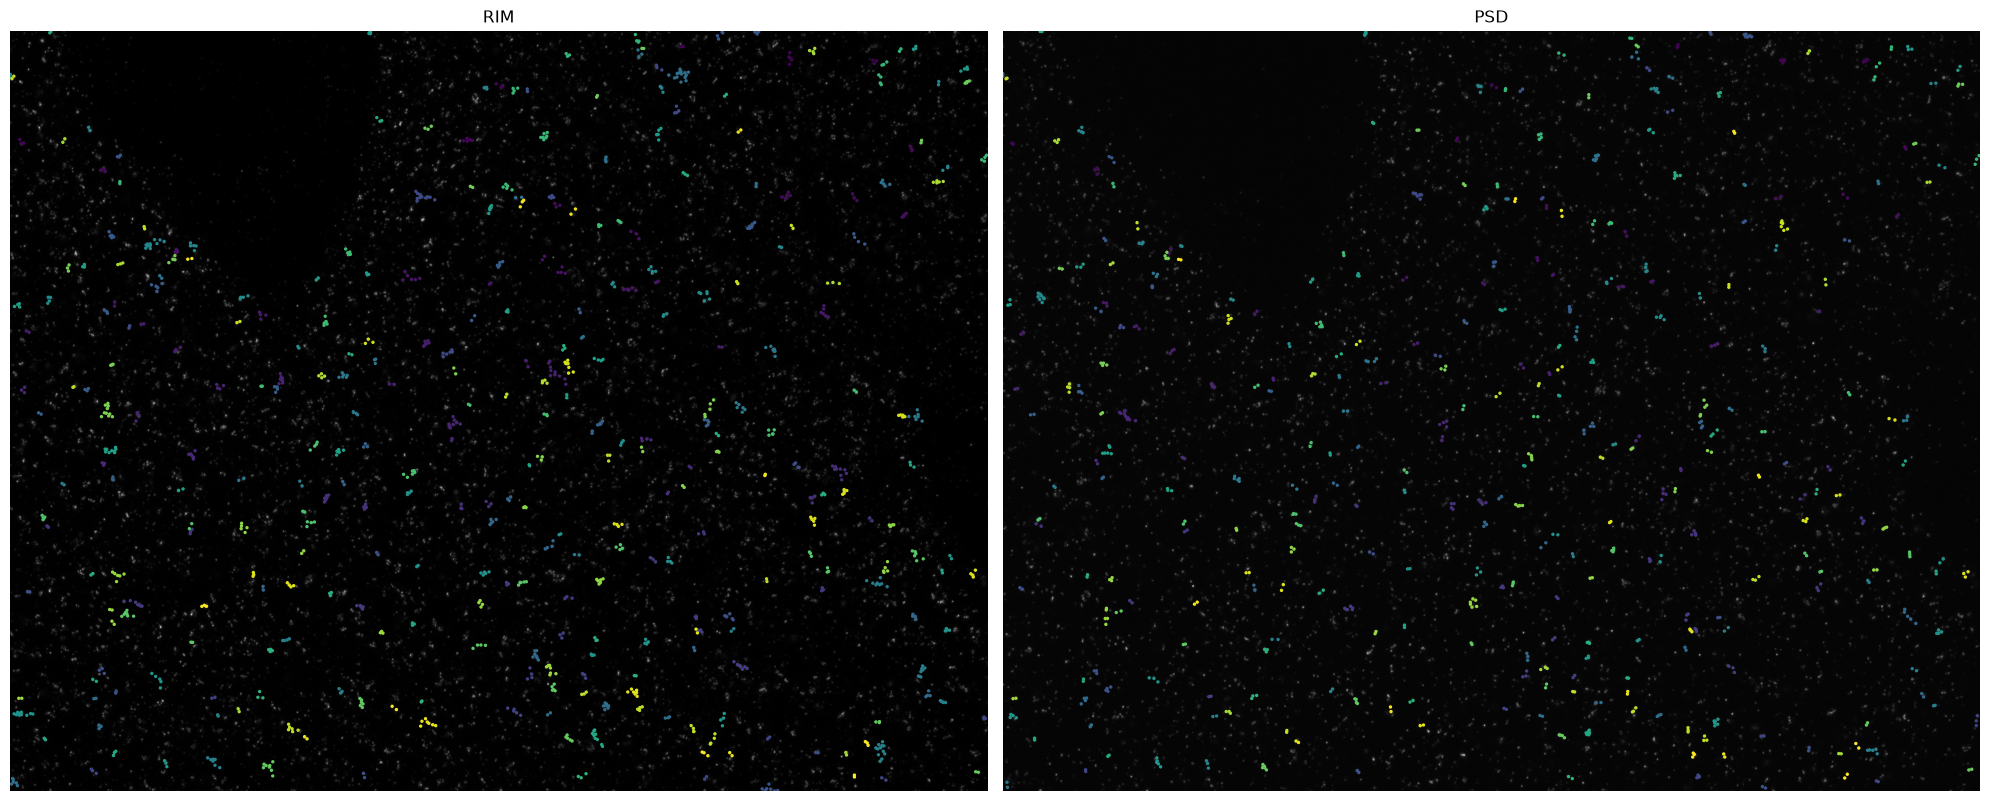

In [140]:
from prrt_clustering import find_synapses, plot_clusters
import pandas as pd

spoints, clusters, synapses = find_synapses(points, eps=1.5, min_samples=2, distance=1.)
# points = spoints[spoints["noise"]==False]
fig = plt.figure(figsize=(20, 20))
fig, axes = plot_data(tmp.sel(C=["RIM","PSD"]), split=True, fig=fig)
# fig, axes = plot_points(clusters, split=True, axes_dict=axes)
# plot_points(spoints, ms=0.5, split=True, axes_dict=axes)
x = spoints[(spoints["synapse"]>=0)&(spoints["C"]=="RIM")]
axes["RIM"].scatter(x['X'],x['Y'],c=x['synapse'],s=2)
x = spoints[(spoints["synapse"]>=0)&(spoints["C"]=="PSD")]
axes["PSD"].scatter(x['X'],x['Y'],c=x['synapse'],s=2)


In [130]:
from prrt_clustering.clustering import quantification

df = quantification(spoints, 0.5)
df

,PRRT,A1,PSD,RIM
0,0,1,3,5
1,2,2,7,5
2,0,3,3,4
3,1,1,2,3
4,2,2,3,6
...,...,...,...,...
328,0,0,2,3
329,3,2,2,2
330,0,0,2,3
331,0,2,6,6


In [116]:
# PRRT1 at GluA1-containing synapse
num_synapses = len(df)
num_prrt = len(points[points["C"]=="PRRT"])
num_a1 = len(points[points["C"]=="A1"])
num_psd = len(points[points["C"]=="PSD"])
num_rim = len(points[points["C"]=="RIM"])
num_a1_synapses = (df["A1"] > 0).sum()
num_psd_clusters = spoints[spoints["C"]=="PSD"]["cluster"].nunique()-1
num_rim_clusters = spoints[spoints["C"]=="RIM"]["cluster"].nunique()-1
num_a1_prrt_synapses = ((df["PRRT"] > 0) & ( df["A1"] > 0)).sum()
{
    "Number of PRRT puncta": num_prrt,
    "Number of A1 puncta": num_a1,
    "Number of PSD puncta": num_psd,
    "Number of RIM puncta": num_rim,
    "Number of PSD cluster": num_psd_clusters,
    "Number of RIM cluster": num_rim_clusters,
    "Number of synpases (PSD+RIM)": num_synapses,
    "Number of GluA1-containing synapse":int(num_a1_synapses),
    "Fraction of PRRT1 at GluA1-containing synapse [%]":float(100.*num_a1_prrt_synapses/num_a1_synapses),
 }


{'Number of PRRT puncta': 6255,
 'Number of A1 puncta': 6225,
 'Number of PSD puncta': 4730,
 'Number of RIM puncta': 9403,
 'Number of PSD cluster': 326,
 'Number of RIM cluster': 1088,
 'Number of synpases (PSD+RIM)': 97,
 'Number of GluA1-containing synapse': 78,
 'Fraction of PRRT1 at GluA1-containing synapse [%]': 79.48717948717949}

,Z,Y,X,C,V,A
0,0.153818,0.149010,205.167973,PRRT,275.0,25.0
1,0.000000,0.180693,151.611890,PRRT,246.0,14.0
2,0.177118,0.628436,168.815353,PRRT,791.0,68.0
3,0.132973,0.827728,162.309725,PRRT,555.0,48.0
4,0.075618,1.004121,118.786636,PRRT,849.0,55.0
...,...,...,...,...,...,...
26608,3.335286,163.663923,89.152292,RIM,2219.0,36.0
26609,3.470539,163.919371,180.506413,RIM,241.0,13.0
26610,3.527988,164.213364,26.198455,RIM,979.0,27.0
26611,3.465517,164.474160,180.971788,RIM,725.0,25.0
